# Análisis Exploratorio de Datos: CounselChat

Este cuaderno documenta el análisis exploratorio del conjunto de datos
CounselChat en el marco del Trabajo de Fin de Grado sobre Ranking de
respuestas terapéuticas en conversaciones de apoyo en salud mental.

El objetivo del análisis es doble: por un lado, caracterizar el conjunto de
datos (volumen, temas, calidad); por otro, y de forma más relevante, evaluar
su idoneidad para la tarea de ranking, prestando especial atención a los
*upvotes* como señal de calidad y a la estructura de respuestas por pregunta.


**Configuración del entorno y carga de datos**

Se prepara el entorno de forma reproducible, se fija una semilla aleatoria
común a todo el proyecto y se establece una estética uniforme para todas las
figuras, de modo que las visualizaciones mantengan un aspecto coherente en la
memoria. A continuación se carga CounselChat directamente desde su repositorio
oficial en Hugging Face.

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [82]:
# Reproducibilidad: misma semilla, mismos resultados en cada ejecución
RANDOM_SEED = 27
np.random.seed(RANDOM_SEED)

In [83]:
# Estética coherente para todas las figuras de la memoria
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

In [84]:
# Carga del dataset desde Hugging Face

from datasets import load_dataset
dataset = load_dataset("nbertagnolli/counsel-chat")
df = dataset["train"].to_pandas()

Repo card metadata block was not found. Setting CardData to empty.


**Descripción del conjunto de datos**

In [85]:
print("Dimensiones (filas, columnas):", df.shape)
print("\nColumnas disponibles:")
print(list(df.columns))

Dimensiones (filas, columnas): (2775, 10)

Columnas disponibles:
['questionID', 'questionTitle', 'questionText', 'questionLink', 'topic', 'therapistInfo', 'therapistURL', 'answerText', 'upvotes', 'views']


El conjunto de datos contiene 2.775 respuestas. Cada fila corresponde a la respuesta de un profesional a una pregunta publicada en CounselChat.

Las variables principales son:

- questionID: Identificador único de la pregunta. Permite agrupar las distintas respuestas asociadas a una misma consulta.
- questionTitle: Título de la pregunta.
- questionText: Texto de la pregunta realizada por el usuario.
- questionLink: Enlace original a la pregunta en CounselChat.
- topic: Tema o categoría clínica de la consulta.
- therapistInfo: Información disponible sobre el profesional que responde.
- therapistURL: Enlace al perfil del profesional en CounselChat.
- answerText: Texto de la respuesta proporcionada por el profesional.
- upvotes: Número de votos positivos recibidos por la respuesta.
- views: Número de visualizaciones asociadas a la pregunta/respuesta.

## BLOQUE 1: Inspección inicial y calidad de los datos

Objetivo: antes de analizar, verificar la integridad del dataset. Un EDA riguroso empieza comprobando tipos, nulos y duplicados, porque cualquier conclusión posterior depende de datos limpios.

**1.1 Vista rápida de las primeras filas**

In [86]:
display(df.head(3))

,questionID,questionTitle,questionText,questionLink,topic,therapistInfo,therapistURL,answerText,upvotes,views
0,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Jennifer MolinariHypnotherapist & Licensed Cou...,https://counselchat.com/therapists/jennifer-mo...,It is very common for people to have multiple ...,3,1971
1,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,"Jason Lynch, MS, LMHC, LCAC, ADSIndividual & C...",https://counselchat.com/therapists/jason-lynch...,"I've never heard of someone having ""too many i...",2,386
2,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Shakeeta TorresFaith Based Mental Health Couns...,https://counselchat.com/therapists/shakeeta-to...,Absolutely not. I strongly recommending worki...,2,3071


**1.2 Tipos de datos y memoria**

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2775 entries, 0 to 2774
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   questionID     2775 non-null   int64 
 1   questionTitle  2775 non-null   object
 2   questionText   2636 non-null   object
 3   questionLink   2775 non-null   object
 4   topic          2775 non-null   object
 5   therapistInfo  2775 non-null   object
 6   therapistURL   2775 non-null   object
 7   answerText     2749 non-null   object
 8   upvotes        2775 non-null   int64 
 9   views          2775 non-null   int64 
dtypes: int64(3), object(7)
memory usage: 216.9+ KB


**1.3 Valores nulos por columna (absolutos y porcentaje)**

In [88]:
nulos = pd.DataFrame({
    "n_nulos": df.isnull().sum(),
    "porcentaje": (df.isnull().sum() / len(df) * 100).round(2)
})
print(nulos)

               n_nulos  porcentaje
questionID           0        0.00
questionTitle        0        0.00
questionText       139        5.01
questionLink         0        0.00
topic                0        0.00
therapistInfo        0        0.00
therapistURL         0        0.00
answerText          26        0.94
upvotes              0        0.00
views                0        0.00


**1.4 Filas duplicadas exactas**

In [89]:
print("Filas completamente duplicadas:", df.duplicated().sum())

Filas completamente duplicadas: 0


**1.5 ¿Cuántas preguntas únicas y cuántas respuestas?**

In [90]:
print("Nº total de respuestas (filas):", len(df))
print("Nº de preguntas únicas (questionID):", df["questionID"].nunique())
print("Nº de temas clínicos únicos (topic):", df["topic"].nunique())
print("Nº de terapeutas únicos:", df["therapistURL"].nunique())

Nº total de respuestas (filas): 2775
Nº de preguntas únicas (questionID): 940
Nº de temas clínicos únicos (topic): 31
Nº de terapeutas únicos: 433


### Interpretación: calidad y estructura de los datos

La inspección inicial revela un conjunto de datos de buena calidad general,
con matices relevantes para la tarea de ranking:

- **Volumen y cardinalidad:** El dataset contiene 2.775 respuestas
  correspondientes a 940 preguntas únicas, respondidas por 433 terapeutas
  distintos y distribuidas en 31 temas clínicos. Esto arroja una media
  aproximada de **2,95 respuestas por pregunta**, cifra que confirma la
  viabilidad de una tarea de ranking: para ordenar respuestas es necesario
  que exista más de una candidata por pregunta. No obstante, al tratarse de
  una media, es imprescindible analizar posteriormente la distribución real
  del número de respuestas por pregunta.

- **Valores nulos:** Se detectan 26 respuestas vacías (answerText, 0,94 %) y
  139 preguntas sin texto (questionText, 5,01 %). Las respuestas vacías
  deberán eliminarse antes de construir el conjunto de ranking, ya que una
  respuesta inexistente no puede ordenarse ni evaluarse. Las preguntas sin
  texto son recuperables parcialmente a través del campo questionTitle, por
  lo que su tratamiento se decidirá en la fase de construcción del dataset.

- **Integridad:** No existen filas completamente duplicadas y los tipos de
  datos son coherentes: upvotes y views son enteros, lo que permite su
  análisis numérico directo como señales de calidad y popularidad.

## BLOQUE 2: Distribución del número de respuestas por pregunta

La tarea de ranking exige que cada pregunta cuente con al menos dos respuestas
candidatas. Este apartado cuantifica qué proporción del conjunto de datos
cumple esa condición y caracteriza la forma de la distribución.

Estadísticas:

In [91]:
# Número de respuestas asociadas a cada pregunta
respuestas_por_pregunta = df.groupby("questionID").size()

# Resumen estadístico presentado como tabla
resumen = respuestas_por_pregunta.describe().round(2).to_frame("valor")
resumen.index.name = "estadístico"
display(resumen)

,valor
estadístico,
count,940.00
mean,2.95
std,6.31
min,1.00
25%,1.00
50%,1.00
75%,3.00
max,107.00


Viabilidad del ranking:

In [92]:
una_sola = (respuestas_por_pregunta == 1).sum()
dos_o_mas = (respuestas_por_pregunta >= 2).sum()
total_preg = len(respuestas_por_pregunta)

viabilidad = pd.DataFrame({
    "n_preguntas": [una_sola, dos_o_mas, total_preg],
    "porcentaje": [
        round(una_sola / total_preg * 100, 1),
        round(dos_o_mas / total_preg * 100, 1),
        100.0
    ]
}, index=["1 respuesta (no rankeable)", "2+ respuestas (rankeable)", "Total"])

display(viabilidad)

,n_preguntas,porcentaje
1 respuesta (no rankeable),480,51.1
2+ respuestas (rankeable),460,48.9
Total,940,100.0


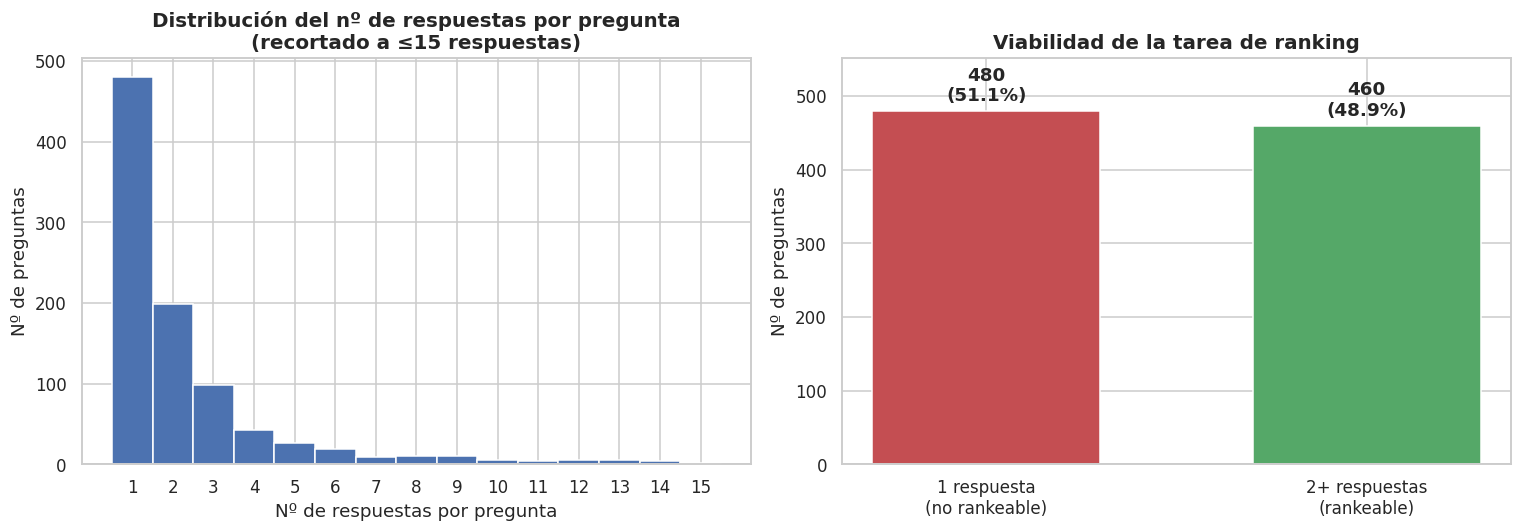

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución recortada: el máximo (107) comprime la escala y oculta la forma real
LIMITE = 15
recortado = respuestas_por_pregunta[respuestas_por_pregunta <= LIMITE]
axes[0].hist(recortado, bins=range(1, LIMITE + 2),
             edgecolor="white", align="left", color="#4C72B0")
axes[0].set_title(f"Distribución del nº de respuestas por pregunta\n(recortado a ≤{LIMITE} respuestas)")
axes[0].set_xlabel("Nº de respuestas por pregunta")
axes[0].set_ylabel("Nº de preguntas")
axes[0].set_xticks(range(1, LIMITE + 1))

# Preguntas utilizables frente a descartadas para la tarea de ranking
barras = axes[1].bar(
    ["1 respuesta\n(no rankeable)", "2+ respuestas\n(rankeable)"],
    [una_sola, dos_o_mas],
    color=["#C44E52", "#55A868"], edgecolor="white", width=0.6
)
axes[1].set_title("Viabilidad de la tarea de ranking")
axes[1].set_ylabel("Nº de preguntas")

for barra, valor in zip(barras, [una_sola, dos_o_mas]):
    axes[1].text(barra.get_x() + barra.get_width() / 2, valor + 8,
                 f"{valor}\n({valor / total_preg * 100:.1f}%)",
                 ha="center", va="bottom", fontweight="bold")
axes[1].set_ylim(0, max(una_sola, dos_o_mas) * 1.15)

plt.tight_layout()
plt.savefig("figura_3_1.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretación: viabilidad de la tarea de ranking

Este análisis constituye uno de los hallazgos centrales del estudio
exploratorio, ya que determina qué subconjunto de datos es realmente
utilizable para la tarea de ranking.

**Más de la mitad de las preguntas (51,1 %, es decir, 480 de 940) reciben una
única respuesta.** Estas preguntas no son rankeables por definición: ordenar
respuestas requiere al menos dos candidatas por pregunta. En consecuencia, el
conjunto efectivo para la evaluación del ranking se reduce a las **460
preguntas (48,9 %) que disponen de dos o más respuestas**.

La distribución del número de respuestas por pregunta presenta además una
marcada **asimetría positiva**. La media (2,95) es casi tres veces superior a
la mediana (1,00), lo que indica que el valor promedio no es representativo del
caso típico: la mayoría de preguntas tienen una sola respuesta, mientras que
un reducido número de preguntas concentra un volumen muy elevado, alcanzando un
máximo de 107 respuestas. Esta observación matiza la media de 2,95 respuestas
por pregunta calculada inicialmente, que resultaba engañosa al no reflejar la
forma real de la distribución.

**Decisión derivada del análisis:** el conjunto de datos para la tarea de
ranking se construirá filtrando las preguntas con dos o más respuestas,
descartando las 480 preguntas de respuesta única. Esta decisión se documenta
aquí y se aplicará en la fase de construcción del dataset.

## BLOQUE 3: Análisis de los *upvotes* como señal de calidad

Los *upvotes* constituyen la señal de referencia empleada en este trabajo para
determinar qué respuesta es la más adecuada. Su idoneidad como medida de
calidad no puede darse por supuesta: si la mayoría de respuestas carecen de
valoración, o si las valoraciones se concentran en unos pocos casos, la señal
resultará débil y condicionará la evaluación de los sistemas de ranking.

Este apartado examina la distribución de los *upvotes* y, de forma especialmente
relevante, su comportamiento dentro de cada pregunta, que es el nivel al que
opera realmente la tarea de ranking.

Distribución global de upvotes:

In [94]:
resumen_upvotes = df["upvotes"].describe().round(2).to_frame("valor")
resumen_upvotes.index.name = "estadístico"
display(resumen_upvotes)

# Proporción de respuestas sin ninguna valoración
sin_upvotes = (df["upvotes"] == 0).sum()
con_upvotes = (df["upvotes"] > 0).sum()

distribucion_señal = pd.DataFrame({
    "n_respuestas": [sin_upvotes, con_upvotes, len(df)],
    "porcentaje": [
        round(sin_upvotes / len(df) * 100, 1),
        round(con_upvotes / len(df) * 100, 1),
        100.0
    ]
}, index=["Sin upvotes (0)", "Con upvotes (>0)", "Total"])

display(distribucion_señal)

,valor
estadístico,
count,2775.00
mean,0.52
std,1.04
min,0.00
25%,0.00
50%,0.00
75%,1.00
max,12.00


,n_respuestas,porcentaje
Sin upvotes (0),1939,69.9
Con upvotes (>0),836,30.1
Total,2775,100.0


Análisis crítico: ¿hay empates dentro de cada pregunta?

In [95]:
# El ranking se evalúa dentro de cada pregunta: interesa saber si los upvotes
# permiten distinguir una "mejor respuesta" o si se producen empates.
rankeables = df[df["questionID"].isin(
    respuestas_por_pregunta[respuestas_por_pregunta >= 2].index
)]

def diagnostico_pregunta(grupo):
    maximo = grupo["upvotes"].max()
    return pd.Series({
        "n_respuestas": len(grupo),
        "upvotes_max": maximo,
        "n_con_maximo": (grupo["upvotes"] == maximo).sum(),
        "todas_cero": (grupo["upvotes"] == 0).all()
    })

diag = rankeables.groupby("questionID").apply(diagnostico_pregunta)

todas_cero = int(diag["todas_cero"].sum())
empate_max = int(((diag["n_con_maximo"] > 1) & (~diag["todas_cero"])).sum())
ganador_claro = int((diag["n_con_maximo"] == 1).sum())
total_rank = len(diag)

calidad_señal = pd.DataFrame({
    "n_preguntas": [ganador_claro, empate_max, todas_cero, total_rank],
    "porcentaje": [
        round(ganador_claro / total_rank * 100, 1),
        round(empate_max / total_rank * 100, 1),
        round(todas_cero / total_rank * 100, 1),
        100.0
    ]
}, index=[
    "Mejor respuesta única (señal útil)",
    "Empate en el máximo (señal ambigua)",
    "Todas con 0 upvotes (sin señal)",
    "Total preguntas rankeables"
])

display(calidad_señal)

/tmp/ipykernel_700/1004069360.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  diag = rankeables.groupby("questionID").apply(diagnostico_pregunta)


,n_preguntas,porcentaje
Mejor respuesta única (señal útil),214,46.5
Empate en el máximo (señal ambigua),62,13.5
Todas con 0 upvotes (sin señal),184,40.0
Total preguntas rankeables,460,100.0


Visualización:

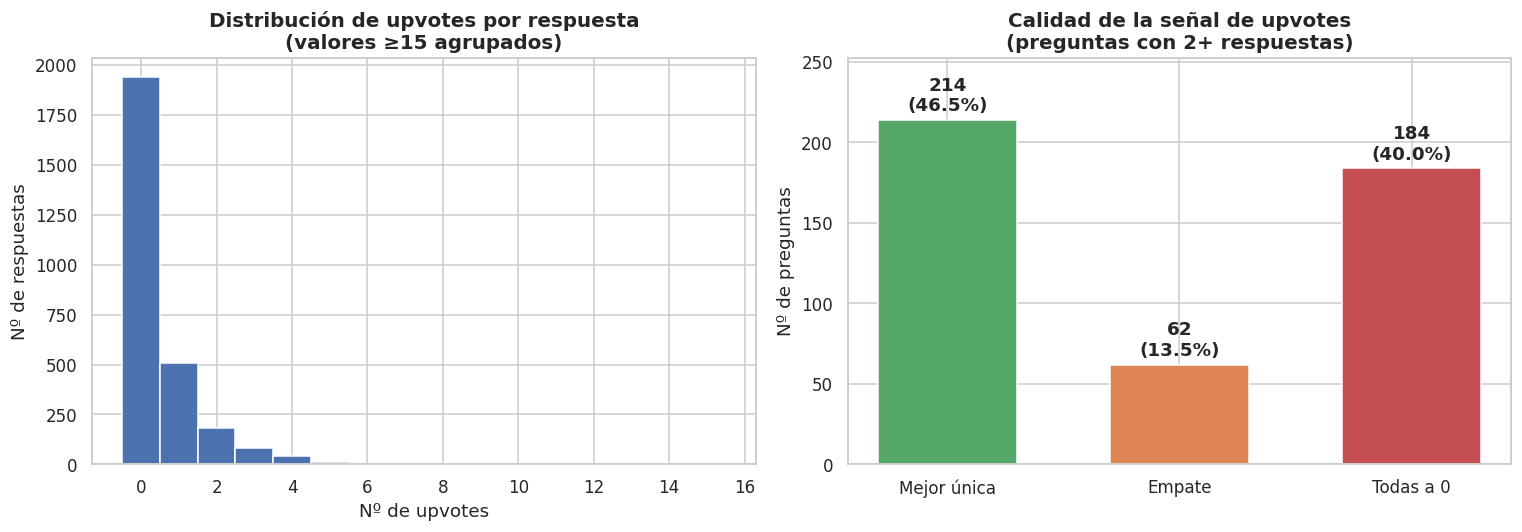

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de upvotes, recortada porque unos pocos valores extremos
# comprimirían la escala y ocultarían la concentración en valores bajos
LIM_UP = 15
axes[0].hist(df["upvotes"].clip(upper=LIM_UP), bins=range(0, LIM_UP + 2),
             edgecolor="white", align="left", color="#4C72B0")
axes[0].set_title(f"Distribución de upvotes por respuesta\n(valores ≥{LIM_UP} agrupados)")
axes[0].set_xlabel("Nº de upvotes")
axes[0].set_ylabel("Nº de respuestas")

# Calidad de la señal dentro de las preguntas rankeables
etiquetas = ["Mejor única", "Empate", "Todas a 0"]
valores = [ganador_claro, empate_max, todas_cero]
colores = ["#55A868", "#DD8452", "#C44E52"]
barras = axes[1].bar(etiquetas, valores, color=colores, edgecolor="white", width=0.6)
axes[1].set_title("Calidad de la señal de upvotes\n(preguntas con 2+ respuestas)")
axes[1].set_ylabel("Nº de preguntas")

for barra, valor in zip(barras, valores):
    axes[1].text(barra.get_x() + barra.get_width() / 2, valor + 3,
                 f"{valor}\n({valor / total_rank * 100:.1f}%)",
                 ha="center", va="bottom", fontweight="bold")
axes[1].set_ylim(0, max(valores) * 1.18)

plt.tight_layout()
plt.savefig("figura_3_2.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretación: los *upvotes* como señal débil

El análisis de los *upvotes* revela una limitación fundamental del conjunto de
datos que condiciona el diseño de la evaluación.

**La señal es escasa.** El 69,9 % de las respuestas (1.939 de 2.775) no ha
recibido ninguna valoración. La media se sitúa en 0,52 *upvotes* por respuesta
y el valor máximo observado es 12, lo que evidencia un rango muy estrecho.

**Más relevante aún es el comportamiento de la señal a nivel de pregunta**, que
es el nivel al que opera la tarea de ranking. De las 460 preguntas con dos o
más respuestas:

- En **184 preguntas (40,0 %) todas las respuestas tienen cero *upvotes***. En
  estos casos no existe una respuesta de referencia: la señal no permite
  determinar cuál es la mejor y cualquier ordenación resulta indistinguible.
- En **62 preguntas (13,5 %) se produce un empate en el valor máximo**, de modo
  que dos o más respuestas comparten la mejor valoración. La noción de "única
  respuesta correcta" que subyace a la métrica Precision@1 resulta ambigua en
  estos casos.
- Únicamente en **214 preguntas (46,5 %) existe una única respuesta con la
  valoración máxima**, configurando una señal de referencia inequívoca.

**Decisión derivada del análisis:** La evaluación de los sistemas de ranking se
restringirá al subconjunto de preguntas que presentan una mejor respuesta
inequívoca, dado que las preguntas sin señal no permiten discriminar entre
sistemas y las preguntas con empate introducen ambigüedad en la métrica. El
tratamiento de los empates se documentará explícitamente en la fase de
construcción del conjunto de evaluación.

Este hallazgo confirma la naturaleza de **señal débil** de los *upvotes*,
asumida desde el planteamiento del trabajo, y cuantifica su alcance real: el
conjunto efectivo de evaluación se reduce de las 940 preguntas iniciales a 214,
un 22,8 % del total.

### Análisis del preference score

Hago el cálculo de preference score

In [97]:
df_score = df.copy()

# Aseguramos que views y upvotes sean numéricos
df_score["views"] = pd.to_numeric(df_score["views"], errors="coerce")
df_score["upvotes"] = pd.to_numeric(df_score["upvotes"], errors="coerce")

# El score no está definido cuando views = 0
df_score["preference_score"] = np.where(
    df_score["views"] > 0,
    np.log1p(df_score["upvotes"]) / np.log1p(df_score["views"]),
    np.nan
)

print("Respuestas totales:", len(df_score))
print("Respuestas con views = 0:", (df_score["views"] == 0).sum())
print("Scores no calculables:", df_score["preference_score"].isna().sum())

df_score[["questionID", "upvotes", "views", "preference_score"]].head()

Respuestas totales: 2775
Respuestas con views = 0: 0
Scores no calculables: 0


,questionID,upvotes,views,preference_score
0,0,3,1971,0.182724
1,0,2,386,0.184380
2,0,2,3071,0.136812
3,0,2,2643,0.139417
4,0,1,256,0.124912


Me quedo con las que tengan al menos dos respuestas, pues si una pregunta solo tiene una respuesta, no existe realmente un problema de ranking.

In [98]:
n_respuestas = df_score.groupby("questionID").size()

ids_multi = n_respuestas[n_respuestas >= 2].index

df_rank = df_score[
    df_score["questionID"].isin(ids_multi)
].copy()

print("Preguntas totales:", df_score["questionID"].nunique())
print("Preguntas con >= 2 respuestas:", df_rank["questionID"].nunique())
print("Respuestas incluidas en el análisis:", len(df_rank))

Preguntas totales: 940
Preguntas con >= 2 respuestas: 460
Respuestas incluidas en el análisis: 2295


Comparo el ganador por upvotes con el ganador por score (en el código tengo en cuenta que puede haber empates):

In [99]:
# Preguntas en las que existe alguna señal de preferencia
ids_con_preferencia = (
    df_rank.groupby("questionID")["preference_score"]
    .max()
)

ids_con_preferencia = ids_con_preferencia[
    ids_con_preferencia > 0
].index

df_preferencia = df_rank[
    df_rank["questionID"].isin(ids_con_preferencia)
].copy()

print("Preguntas con señal de preferencia:",
      df_preferencia["questionID"].nunique())

Preguntas con señal de preferencia: 276


In [100]:
resultados = []

for question_id, grupo in df_preferencia.groupby("questionID"):

    # Eliminamos respuestas sin score calculable
    grupo_valido = grupo.dropna(subset=["preference_score"])

    if len(grupo_valido) < 2:
        continue

    max_upvotes = grupo_valido["upvotes"].max()
    max_score = grupo_valido["preference_score"].max()

    # Puede haber varias respuestas empatadas en el máximo
    top_upvotes = set(
        grupo_valido.index[grupo_valido["upvotes"] == max_upvotes]
    )

    top_score = set(
        grupo_valido.index[grupo_valido["preference_score"] == max_score]
    )

    # Consideramos coincidencia si al menos una respuesta
    # pertenece a ambos conjuntos de ganadores
    coincide = len(top_upvotes.intersection(top_score)) > 0

    resultados.append({
        "questionID": question_id,
        "coincide": coincide,
        "max_upvotes": max_upvotes,
        "max_score": max_score,
        "n_respuestas": len(grupo_valido)
    })

comparacion = pd.DataFrame(resultados)

porcentaje_coincidencia = comparacion["coincide"].mean() * 100

print(f"Preguntas analizadas: {len(comparacion)}")
print(
    f"Coincidencia entre ganador por upvotes y ganador por score: "
    f"{porcentaje_coincidencia:.2f}%"
)
print(
    f"Casos de desacuerdo: "
    f"{(~comparacion['coincide']).sum()} "
    f"({100 - porcentaje_coincidencia:.2f}%)"
)

Preguntas analizadas: 276
Coincidencia entre ganador por upvotes y ganador por score: 99.64%
Casos de desacuerdo: 1 (0.36%)


Visualización de coincidencias

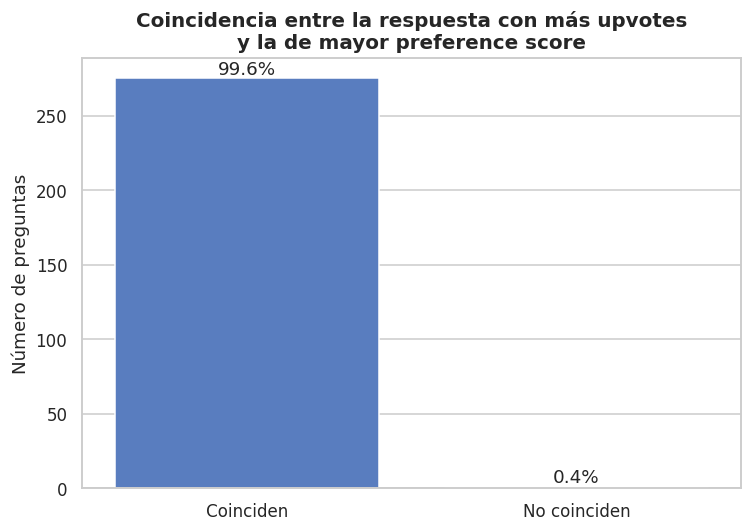

In [101]:
conteo = (
    comparacion["coincide"]
    .map({True: "Coinciden", False: "No coinciden"})
    .value_counts()
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=conteo.index,
    y=conteo.values
)

plt.title("Coincidencia entre la respuesta con más upvotes\ny la de mayor preference score")
plt.xlabel("")
plt.ylabel("Número de preguntas")

for i, valor in enumerate(conteo.values):
    porcentaje = valor / conteo.sum() * 100
    ax.text(
        i,
        valor,
        f"{porcentaje:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Saco los casos donde no coinciden (análisis de desacuerdos):

In [102]:
ids_desacuerdo = comparacion.loc[
    ~comparacion["coincide"],
    "questionID"
]

desacuerdos = df_rank[
    df_rank["questionID"].isin(ids_desacuerdo)
].copy()

desacuerdos = desacuerdos.sort_values(
    ["questionID", "upvotes"],
    ascending=[True, False]
)

print("Número de preguntas con desacuerdo:", len(ids_desacuerdo))

desacuerdos[
    [
        "questionID",
        "answerText",
        "upvotes",
        "views",
        "preference_score"
    ]
].head(20)

Número de preguntas con desacuerdo: 1


,questionID,answerText,upvotes,views,preference_score
0,0,It is very common for people to have multiple ...,3,1971,0.182724
1,0,"I've never heard of someone having ""too many i...",2,386,0.184380
2,0,Absolutely not. I strongly recommending worki...,2,3071,0.136812
3,0,Let me start by saying there are never too man...,2,2643,0.139417
4,0,I just want to acknowledge you for the courage...,1,256,0.124912
5,0,It's not really a question of whether you have...,1,435,0.114049
6,0,There is no such thing as too much. Start wher...,1,217,0.128730
7,0,The most direct answer is no. I would venture ...,1,1064,0.099437
8,0,It is never too late to get help and begin mak...,1,1024,0.099986
9,0,You have been through so much and it sounds li...,1,1809,0.092406


En 275 de 276 (99,64 %), la respuesta con mayor preference score coincide con alguna de las respuestas con mayor número de upvotes. Solo se observa un desacuerdo (0,36 %). En ese caso, el score favorece una respuesta con 2 upvotes y 386 visualizaciones frente a otra con 3 upvotes y 1971 visualizaciones, reflejando el efecto de normalizar por el nivel de exposición( penalizar, en cierta medida, que una respuesta haya tenido mucha más exposición).

Distribución del peference score:

count    2295.000000
mean        0.041602
std         0.074715
min         0.000000
25%         0.000000
50%         0.000000
75%         0.096048
max         0.394708
Name: preference_score, dtype: float64
Porcentaje de respuestas con score = 0: 73.64%


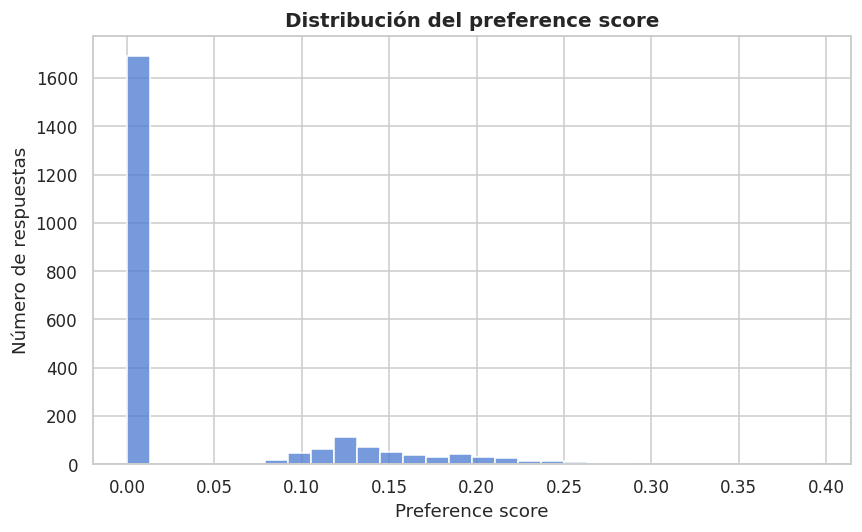

In [103]:
print(df_rank["preference_score"].describe())

print(
    "Porcentaje de respuestas con score = 0:",
    f"{(df_rank['preference_score'] == 0).mean() * 100:.2f}%"
)

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_rank,
    x="preference_score",
    bins=30
)

plt.title("Distribución del preference score")
plt.xlabel("Preference score")
plt.ylabel("Número de respuestas")

plt.tight_layout()
plt.show()

Como quieres predecir “la respuesta más preferida”, necesitas saber si realmente hay una única ganadora por pregunta.

In [123]:
# Empates en el máximo preference score

empates = []

for question_id, grupo in df_rank.groupby("questionID"):

    grupo_valido = grupo.dropna(subset=["preference_score"])

    if len(grupo_valido) < 2:
        continue

    max_score = grupo_valido["preference_score"].max()

    n_ganadoras = (
        grupo_valido["preference_score"] == max_score
    ).sum()

    empates.append({
        "questionID": question_id,
        "n_respuestas": len(grupo_valido),
        "n_ganadoras": n_ganadoras,
        "empate_top": n_ganadoras > 1
    })

empates_df = pd.DataFrame(empates)

n_empates = empates_df["empate_top"].sum()
porcentaje_empates = empates_df["empate_top"].mean() * 100

print(f"Preguntas analizadas: {len(empates_df)}")
print(f"Preguntas con empate en el primer puesto: {n_empates}")
print(f"Porcentaje con empate: {porcentaje_empates:.2f}%")

Preguntas analizadas: 460
Preguntas con empate en el primer puesto: 184
Porcentaje con empate: 40.00%


Veo cuáles con:

In [124]:
empates_df[empates_df["empate_top"]]

,questionID,n_respuestas,n_ganadoras,empate_top
5,5,3,3,True
6,6,2,2,True
7,7,2,2,True
8,8,2,2,True
9,9,2,2,True
...,...,...,...,...
442,916,2,2,True
445,922,2,2,True
446,925,4,4,True
457,937,11,11,True


In [106]:
# Añadimos el valor máximo del score de cada pregunta
max_scores = (
    df_rank.groupby("questionID")["preference_score"]
    .max()
    .rename("max_score")
)

empates_df = empates_df.merge(
    max_scores,
    on="questionID",
    how="left"
)

# Empates donde el máximo score es 0
empates_cero = empates_df[
    (empates_df["empate_top"]) &
    (empates_df["max_score"] == 0)
]

# Empates donde el máximo score es mayor que 0
empates_positivos = empates_df[
    (empates_df["empate_top"]) &
    (empates_df["max_score"] > 0)
]

print("Empates totales:", empates_df["empate_top"].sum())
print("Empates porque el máximo score es 0:", len(empates_cero))
print("Empates con score positivo:", len(empates_positivos))

Empates totales: 184
Empates porque el máximo score es 0: 184
Empates con score positivo: 0


## BLOQUE 4: Longitud de las respuestas y detección de sesgos

La longitud de una respuesta es una característica superficial fácilmente
explotable por un sistema de ranking. Si las respuestas más extensas tienden a
recibir más *upvotes*, un ranker podría alcanzar buen rendimiento limitándose a
priorizar la extensión, sin capturar realmente la calidad del contenido.

Este apartado caracteriza la longitud de las respuestas y examina su relación
con la señal de calidad, con el fin de anticipar posibles sesgos en la
evaluación.

Caracterización:

In [107]:
df["long_palabras"] = df["answerText"].fillna("").str.split().str.len()
df["long_caracteres"] = df["answerText"].fillna("").str.len()

longitudes = df[df["answerText"].notna()][["long_palabras", "long_caracteres"]]
display(longitudes.describe().round(1))

,long_palabras,long_caracteres
count,2749.0,2749.0
mean,168.0,959.7
std,118.5,677.1
min,1.0,10.0
25%,87.0,498.0
50%,136.0,779.0
75%,212.0,1221.0
max,939.0,5499.0


Relación con los upvotes:

In [108]:
from scipy.stats import spearmanr, pearsonr

valid = df[df["answerText"].notna()]

rho, p_rho = spearmanr(valid["long_palabras"], valid["upvotes"])
r, p_r = pearsonr(valid["long_palabras"], valid["upvotes"])

correlaciones = pd.DataFrame({
    "coeficiente": [round(r, 3), round(rho, 3)],
    "p_valor": [f"{p_r:.2e}", f"{p_rho:.2e}"]
}, index=["Pearson (lineal)", "Spearman (monótona)"])
display(correlaciones)

# Upvotes medios por cuartil de longitud: relación más interpretable
valid = valid.copy()
valid["cuartil_long"] = pd.qcut(valid["long_palabras"], 4,
                                labels=["Q1 (más cortas)", "Q2", "Q3", "Q4 (más largas)"])
por_cuartil = valid.groupby("cuartil_long", observed=True).agg(
    n_respuestas=("upvotes", "size"),
    upvotes_medios=("upvotes", "mean"),
    pct_con_upvotes=("upvotes", lambda x: (x > 0).mean() * 100)
).round(2)
display(por_cuartil)

,coeficiente,p_valor
Pearson (lineal),0.128,1.55e-11
Spearman (monótona),0.151,1.76e-15


,n_respuestas,upvotes_medios,pct_con_upvotes
cuartil_long,,,
Q1 (más cortas),689,0.34,20.17
Q2,688,0.46,28.63
Q3,686,0.58,34.99
Q4 (más largas),686,0.71,37.76


Test decisivo: ¿gana la más larga dentro de cada pregunta?

In [109]:
# Comparación intra-pregunta: en las preguntas con señal inequívoca,
# ¿la respuesta más votada es también la más larga?
con_señal = diag[diag["n_con_maximo"] == 1].index
subset = df[df["questionID"].isin(con_señal) & df["answerText"].notna()]

def gana_la_mas_larga(grupo):
    mejor = grupo.loc[grupo["upvotes"].idxmax()]
    mas_larga = grupo.loc[grupo["long_palabras"].idxmax()]
    return mejor.name == mas_larga.name

coincidencias = subset.groupby("questionID").apply(gana_la_mas_larga)
n_coincide = int(coincidencias.sum())
n_total = len(coincidencias)

# Baseline aleatorio: probabilidad de acertar eligiendo al azar
azar = subset.groupby("questionID").size().apply(lambda n: 1/n).mean() * 100

sesgo = pd.DataFrame({
    "valor": [n_coincide, n_total, round(n_coincide/n_total*100, 1), round(azar, 1)]
}, index=["Preguntas donde la más votada es la más larga",
          "Total preguntas evaluadas",
          "Porcentaje de coincidencia (%)",
          "Baseline aleatorio esperado (%)"])
display(sesgo)

/tmp/ipykernel_700/58907200.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  coincidencias = subset.groupby("questionID").apply(gana_la_mas_larga)


,valor
Preguntas donde la más votada es la más larga,85.0
Total preguntas evaluadas,214.0
Porcentaje de coincidencia (%),39.7
Baseline aleatorio esperado (%),32.5


In [110]:
# ¿La respuesta más votada es también la más vista?
subset_v = df[df["questionID"].isin(con_señal)]

def gana_la_mas_vista(grupo):
    return grupo["upvotes"].idxmax() == grupo["views"].idxmax()

coinc_views = subset_v.groupby("questionID")[["upvotes", "views"]].apply(gana_la_mas_vista)
n_coinc_v = int(coinc_views.sum())

print(f"La más votada es la más vista en {n_coinc_v} de "
      f"{len(coinc_views)} preguntas "
      f"({n_coinc_v / len(coinc_views) * 100:.1f}%)")

La más votada es la más vista en 163 de 214 preguntas (76.2%)


Visualización:

Text(0, 0.5, 'Upvotes medios')

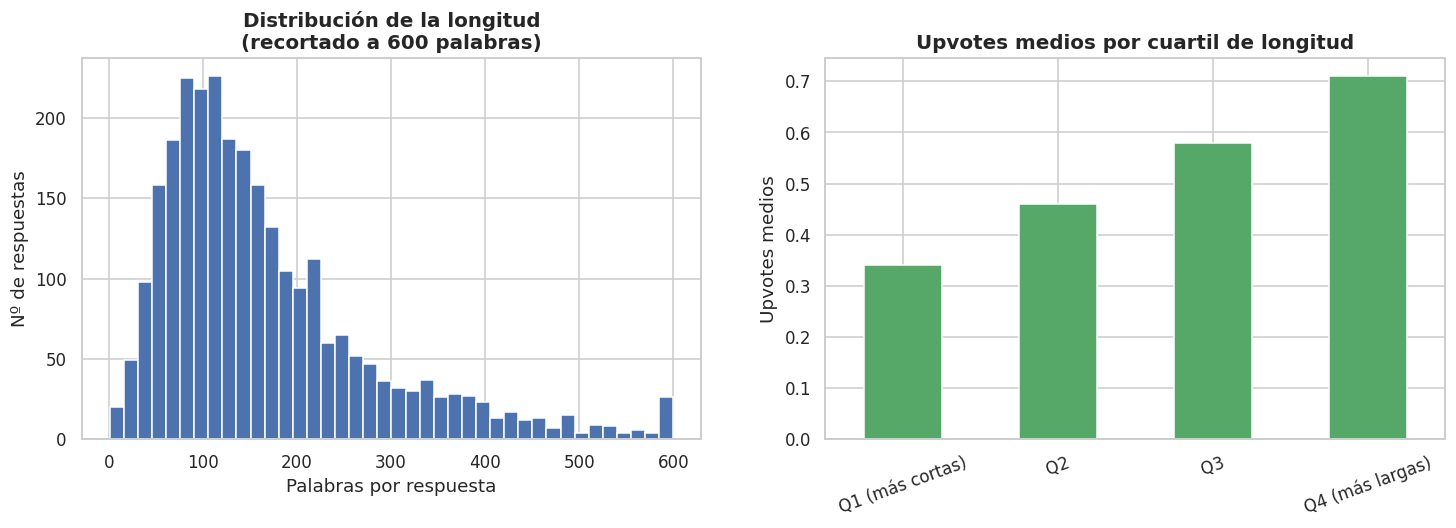

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].hist(valid["long_palabras"].clip(upper=600), bins=40,
             edgecolor="white", color="#4C72B0")
axes[0].set_title("Distribución de la longitud\n(recortado a 600 palabras)")
axes[0].set_xlabel("Palabras por respuesta")
axes[0].set_ylabel("Nº de respuestas")

por_cuartil["upvotes_medios"].plot(kind="bar", ax=axes[1],
                                   color="#55A868", edgecolor="white", rot=20)
axes[1].set_title("Upvotes medios por cuartil de longitud")
axes[1].set_xlabel("")
axes[1].set_ylabel("Upvotes medios")


### Interpretación: existe un sesgo de longitud, pero de magnitud reducida

El análisis identifica una relación positiva entre la extensión de las
respuestas y los *upvotes* recibidos, si bien de intensidad limitada.

**Correlación estadísticamente significativa pero débil.** Los coeficientes de
Pearson (0,128) y Spearman (0,151) resultan significativos (p < 0,001), lo que
se explica en parte por el elevado tamaño muestral (2.749 respuestas). Sin
embargo, su magnitud es reducida: la longitud explica una proporción muy
pequeña de la variabilidad de la señal de calidad. Conviene distinguir aquí
entre significación estadística y relevancia práctica.

**Tendencia monótona por cuartiles.** Los *upvotes* medios aumentan de forma
consistente desde el cuartil de respuestas más cortas (0,34) hasta el de las
más largas (0,71). De modo análogo, la proporción de respuestas que reciben al
menos un voto pasa del 20,2 % al 37,8 %, prácticamente el doble.

**Contraste frente a un baseline aleatorio.** En las 214 preguntas con señal
inequívoca, la respuesta más votada coincide con la más extensa en el 39,7 % de
los casos, frente al 32,5 % que cabría esperar por selección aleatoria. La
diferencia de 7,2 puntos porcentuales confirma la existencia del sesgo, pero
también su carácter moderado: la longitud no determina la valoración recibida.

**Implicaciones para la evaluación:** Este resultado establece un baseline
informativo no trivial, un sistema que ordenase las respuestas únicamente por
extensión alcanzaría un 39,7 % de acierto en Precision@1, que los sistemas
propuestos deberán superar para demostrar que capturan aspectos de calidad no
reducibles a la mera longitud del texto.


## BLOQUE 5: Análisis lingüístico del texto (PLN)

Los apartados anteriores han caracterizado el conjunto de datos a partir de
variables numéricas (número de respuestas, upvotes, longitud, visualizaciones).
Este bloque incorpora una perspectiva lingüística sobre el contenido textual de
preguntas y respuestas, con dos objetivos: identificar el vocabulario
característico de cada rol (paciente frente a terapeuta) y explorar cómo se
organizan semánticamente las preguntas según su tema clínico.

Para ello se emplean dos técnicas habituales en procesamiento de lenguaje
natural: la ponderación *tf-idf*, que resalta los términos distintivos de cada
conjunto de textos frente a los términos comunes, y la proyección *t-SNE*, que
permite visualizar en dos dimensiones la proximidad semántica entre preguntas.

Nubes de palabras con tf-idf (preguntas vs. respuestas):

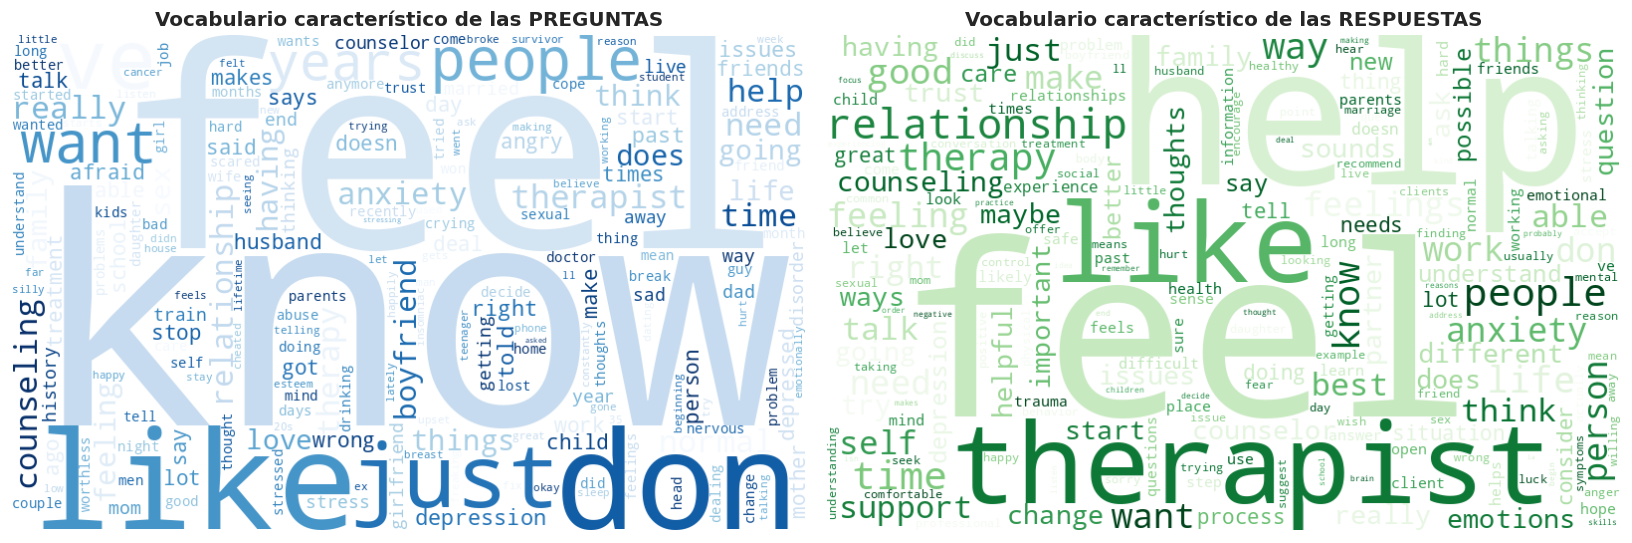

In [112]:
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud

# Recupera el texto de la pregunta usando el título cuando falta el cuerpo,
# igual que se hará en la construcción del dataset
texto_pregunta = df["questionText"].fillna("").str.strip()
falta = texto_pregunta == ""
texto_pregunta = texto_pregunta.mask(falta, df["questionTitle"].fillna(""))

texto_respuesta = df["answerText"].fillna("")

def nube_tfidf(corpus, ax, titulo, color):
    """Calcula el peso tf-idf medio de cada término y dibuja su nube."""
    vec = TfidfVectorizer(stop_words="english", max_features=200, min_df=3)
    X = vec.fit_transform(corpus)
    # Peso medio de cada término sobre todo el corpus: resalta lo característico
    pesos = dict(zip(vec.get_feature_names_out(),
                     np.asarray(X.mean(axis=0)).ravel()))
    wc = WordCloud(width=800, height=500, background_color="white",
                   colormap=color, random_state=RANDOM_SEED
                   ).generate_from_frequencies(pesos)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(titulo)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
nube_tfidf(texto_pregunta, axes[0], "Vocabulario característico de las PREGUNTAS", "Blues")
nube_tfidf(texto_respuesta, axes[1], "Vocabulario característico de las RESPUESTAS", "Greens")
plt.tight_layout()
plt.savefig("figura_4_5a.png", dpi=200, bbox_inches="tight")
plt.show()

Proyección t-SNE de las preguntas por tema usando embeddings SBERT (SBERT captura significado (no solo palabras), por lo que la proyección refleja proximidad semántica entre prgeuntas):

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/17 [00:00<?, ?it/s]

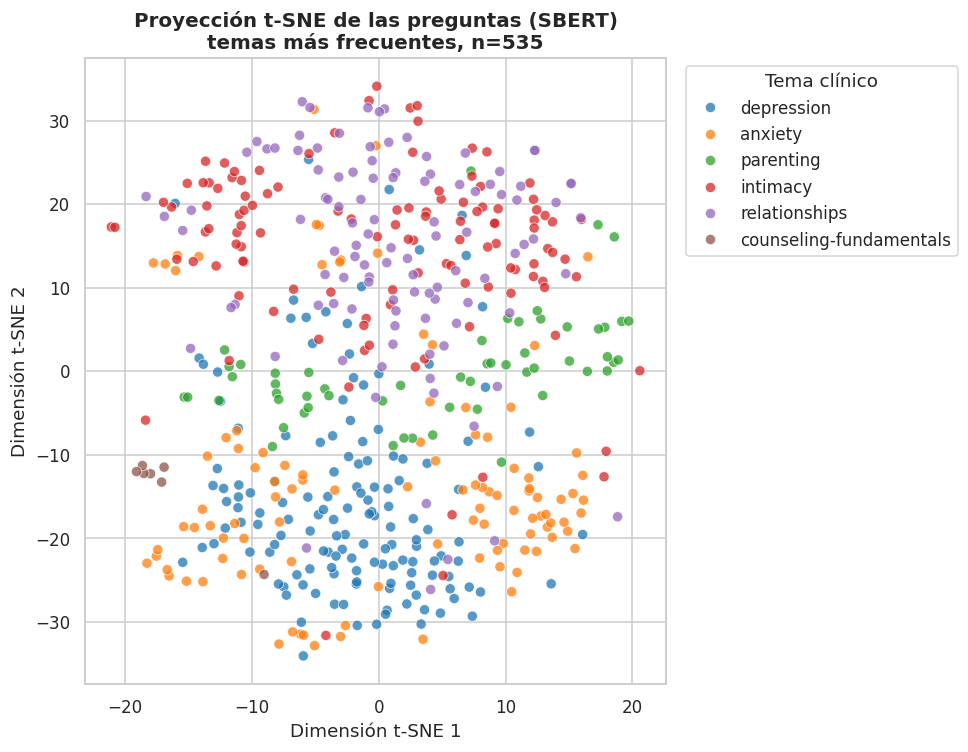

In [113]:
from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE

# Preguntas únicas de los temas más frecuentes (para legibilidad)
TOP_TEMAS = 6
temas_frecuentes = df["topic"].value_counts().head(TOP_TEMAS).index
preguntas_unicas = (
    df.assign(pregunta=texto_pregunta)
      .drop_duplicates("questionID")
      .loc[lambda d: d["topic"].isin(temas_frecuentes)]
      .loc[lambda d: d["pregunta"].str.strip() != ""]
      .reset_index(drop=True)
)

# 1) Codificar las preguntas con SBERT (la primera vez descarga el modelo)
modelo_sbert = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = modelo_sbert.encode(preguntas_unicas["pregunta"].tolist(),
                                 show_progress_bar=True)

# 2) Proyectar a 2D con t-SNE
perplexity = min(30, (len(preguntas_unicas) - 1) // 3)
coords = TSNE(n_components=2, perplexity=perplexity, init="pca",
              learning_rate="auto", random_state=RANDOM_SEED).fit_transform(embeddings)
preguntas_unicas["x"], preguntas_unicas["y"] = coords[:, 0], coords[:, 1]

# 3) Dibujar coloreando por tema
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=preguntas_unicas, x="x", y="y", hue="topic",
                palette="tab10", s=45, alpha=0.75, edgecolor="white", ax=ax)
ax.set_title(f"Proyección t-SNE de las preguntas (SBERT)\n"
             f"temas más frecuentes, n={len(preguntas_unicas)}")
ax.set_xlabel("Dimensión t-SNE 1")
ax.set_ylabel("Dimensión t-SNE 2")
ax.legend(title="Tema clínico", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("figura_5_tsne_sbert.png", dpi=200, bbox_inches="tight")
plt.show()

Análisis de emociones del texto:

In [114]:
# Descargo el léxico NRC. Quitando la dependencia respecto de NRCLex,
# que da problemas al tratar los textos como si fueran rutas de archivo.
import urllib.request
from collections import defaultdict

URL_NRC = "https://raw.githubusercontent.com/dinbav/LeXmo/master/NRC-Emotion-Lexicon-Wordlevel-v0.92.txt"
_raw = urllib.request.urlopen(URL_NRC, timeout=60).read().decode("utf-8")

NRC = defaultdict(set)
for _linea in _raw.splitlines():
    if not _linea.strip():
        continue
    _palabra, _emocion, _valor = _linea.split("\t")
    if _valor == "1":
        NRC[_palabra].add(_emocion)

print("Léxico NRC cargado:", len(NRC), "palabras")

Léxico NRC cargado: 6468 palabras


Preparación:

In [115]:
# Con el léxico NRC directo no hacen falta descargas de nltk ni TextBlob.
# El texto se procesa con expresiones regulares en la celda siguiente.
import re

Calculo del perfil emocional:

In [116]:
EMOCIONES = ["fear", "anger", "sadness", "disgust", "anticipation",
             "surprise", "trust", "joy", "negative", "positive"]

def perfil_emocional(textos):
    """Proporción media de cada emoción NRC sobre un conjunto de textos."""
    acumulado = {e: 0.0 for e in EMOCIONES}
    n = 0
    for t in textos:
        t = str(t).strip()
        if not t:
            continue
        palabras = re.findall(r"[a-z]+", t.lower())
        if not palabras:
            continue
        conteo = {e: 0 for e in EMOCIONES}
        for p in palabras:
            for e in NRC.get(p, ()):
                conteo[e] += 1
        for e in EMOCIONES:
            acumulado[e] += conteo[e] / len(palabras)
        n += 1
    return {e: acumulado[e] / n * 100 for e in EMOCIONES}

perfil_preg = perfil_emocional(texto_pregunta)
perfil_resp = perfil_emocional(texto_respuesta)

comparativa_emo = pd.DataFrame({
    "Preguntas": perfil_preg,
    "Respuestas": perfil_resp
}).round(2)
display(comparativa_emo)

,Preguntas,Respuestas
fear,2.53,1.92
anger,2.25,1.37
sadness,3.02,1.93
disgust,1.23,0.75
anticipation,2.45,2.87
surprise,0.79,1.06
trust,2.86,3.85
joy,1.88,2.36
negative,4.79,2.92
positive,4.03,6.06


Gráfico (barras divergentes por rol):

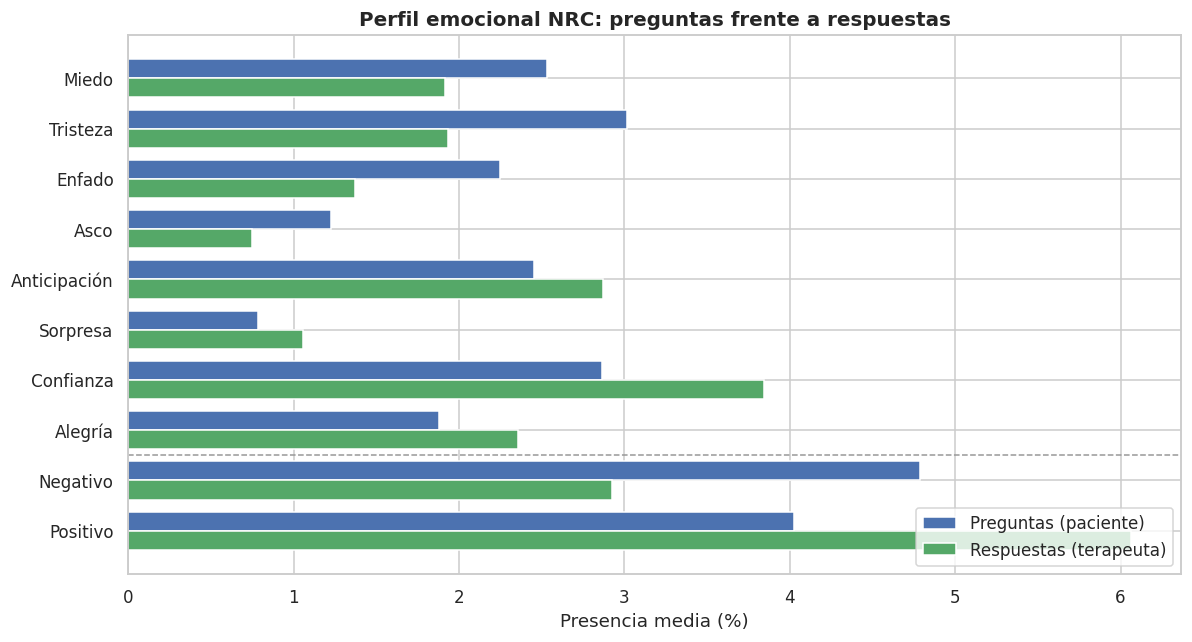

In [117]:
# Ordeno las emociones de más "negativa" a más "positiva" para lectura visual
orden = ["fear", "sadness", "anger", "disgust", "anticipation",
         "surprise", "trust", "joy", "negative", "positive"]
etiquetas = ["Miedo", "Tristeza", "Enfado", "Asco", "Anticipación",
             "Sorpresa", "Confianza", "Alegría", "Negativo", "Positivo"]

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(orden))
alto = 0.38

ax.barh(y - alto/2, [perfil_preg[e] for e in orden], alto,
        label="Preguntas (paciente)", color="#4C72B0", edgecolor="white")
ax.barh(y + alto/2, [perfil_resp[e] for e in orden], alto,
        label="Respuestas (terapeuta)", color="#55A868", edgecolor="white")

ax.set_yticks(y)
ax.set_yticklabels(etiquetas)
ax.invert_yaxis()  # miedo arriba, positivo abajo
ax.set_xlabel("Presencia media (%)")
ax.set_title("Perfil emocional NRC: preguntas frente a respuestas")
ax.legend(loc="lower right")
ax.axhline(7.5, color="#999", linestyle="--", linewidth=1)  # separa emociones de sentimientos

plt.tight_layout()
plt.savefig("figura_nrc_emociones.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretación: patrones lingüísticos y semánticos del texto

El análisis del contenido textual, mediante nubes de palabras ponderadas por
tf-idf y una proyección t-SNE de las preguntas, revela dos hallazgos
complementarios: un contraste de vocabulario entre roles y una organización
semántica de las preguntas por tema clínico.

**Vocabulario característico de cada rol.** Las nubes de palabras muestran un
claro desplazamiento léxico entre preguntas y respuestas. En las preguntas
predominan términos de vivencia emocional en primera persona (feel, know, want)
y de las relaciones personales que motivan la consulta (husband, boyfriend,
parents), configurando un registro centrado en la expresión del malestar. En
las respuestas, el vocabulario se orienta hacia la intervención y el
acompañamiento profesional (therapist, help, therapy, counseling, support),
reflejando el cambio de registro entre quien plantea el problema y quien ofrece
orientación. Cabe señalar la presencia de términos compartidos por ambos roles
(feel, like), coherente con la tendencia de los profesionales a reflejar el
lenguaje del paciente para mantener la coherencia temática.

**Organización semántica de las preguntas.** La proyección t-SNE de los
embeddings SBERT muestra una estructura semántica coherente, con agrupaciones
parciales por tema y solapamientos informativos entre temas afines. Las
preguntas sobre crianza (parenting) se concentran en una región diferenciada, y
las de counseling-fundamentals forman un grupo compacto y separado, coherente
con su carácter distintivo (consultas sobre el propio proceso terapéutico más
que sobre un malestar personal). Los temas de intimidad y relaciones ocupan una
franja común y se solapan entre sí, en línea con su proximidad conceptual. El
solapamiento más marcado se produce entre depresión y ansiedad, que comparten
una amplia región sin frontera nítida, resultado consistente con su elevada
comorbilidad y su vocabulario compartido.

**Contraste emocional entre roles.** El análisis con el léxico NRC confirma un giro afectivo entre pregunta y respuesta. En las preguntas predominan las emociones negativas (miedo, tristeza, enfado y asco), coherente con que el paciente expone un malestar, mientras que las respuestas del terapeuta desplazan el peso hacia la confianza, la anticipación y un tono positivo, propio de una intervención orientada al acompañamiento. Este contraste refuerza la conclusión anterior: pregunta y respuesta no solo difieren en vocabulario, sino también en su carga emocional, lo que apoya de nuevo la insuficiencia de un emparejamiento basado en coincidencia de términos.

**Implicación para la tarea de ranking.** Ambos análisis aportan conclusiones
útiles para el diseño del sistema. En primer lugar, las nubes de palabras
muestran que preguntas y respuestas emplean vocabularios distintos: el paciente
describe su malestar (feel, know, want) mientras que el terapeuta responde con
un lenguaje orientado a la ayuda (therapist, help, therapy), de modo que ambos
apenas comparten términos además de la diferencia de carga emocional. Esto implica que un sistema que se limitase a buscar
palabras coincidentes entre la pregunta y las respuestas fallaría, ya que una
respuesta adecuada rara vez repite las palabras de la pregunta. En la fase preliminar del trabajo, este resultado justificó el uso de recuperación densa (SBERT), capaz de emparejar pregunta y respuesta por su significado y no por las palabras exactas.

En segundo lugar, la proyección t-SNE muestra que algunos temas se solapan,
en especial depresión y ansiedad, lo que indica que existen preguntas de
distintos temas muy similares entre sí. Cuando dos preguntas son parecidas, una
respuesta escrita para una puede ser válida también para la otra. Esto tiene una
consecuencia sobre la evaluación: si el sistema recupera una de esas respuestas
igualmente válidas, el criterio binario la marcará como error por no coincidir
con la respuesta original, penalizando un acierto real. Por ello, cabe esperar
que las métricas ofrezcan una estimación conservadora del rendimiento del
sistema.

## BLOQUE 6: Temas clínicos y exposición de las respuestas

Este último apartado aborda dos cuestiones complementarias. En primer lugar, la
distribución de las preguntas por tema clínico, que caracteriza el dominio
cubierto por el conjunto de datos y permite detectar posibles desequilibrios.

En segundo lugar, la relación entre los *upvotes* y el número de
visualizaciones (views). Esta comparación resulta especialmente pertinente:
si los *upvotes* dependen en gran medida de la exposición recibida por una
respuesta, estarían midiendo visibilidad antes que calidad, lo que constituiría
una limitación adicional de la señal de referencia.

Temas clínicos:

In [118]:
temas = df.groupby("topic").agg(
    n_respuestas=("upvotes", "size"),
    n_preguntas=("questionID", "nunique"),
    upvotes_medios=("upvotes", "mean"),
    pct_con_upvotes=("upvotes", lambda x: (x > 0).mean() * 100)
).round(2).sort_values("n_respuestas", ascending=False)

display(temas)

,n_respuestas,n_preguntas,upvotes_medios,pct_con_upvotes
topic,,,,
depression,465,144,0.42,26.24
anxiety,358,105,0.40,23.46
counseling-fundamentals,270,7,0.17,11.48
intimacy,248,116,0.62,39.52
relationships,202,107,0.93,46.53
parenting,191,56,0.46,28.80
family-conflict,144,63,0.76,40.97
trauma,102,26,0.45,27.45
self-esteem,100,49,0.58,32.00


Views con upvotes:

In [119]:
resumen_views = df["views"].describe().round(1).to_frame("valor")
resumen_views.index.name = "estadístico"
display(resumen_views)

rho_v, p_v = spearmanr(df["views"], df["upvotes"])
r_v, p_vp = pearsonr(df["views"], df["upvotes"])

corr_views = pd.DataFrame({
    "coeficiente": [round(r_v, 3), round(rho_v, 3)],
    "p_valor": [f"{p_vp:.2e}", f"{p_v:.2e}"]
}, index=["Pearson (lineal)", "Spearman (monótona)"])
display(corr_views)

# Upvotes medios por cuartil de visualizaciones
df_v = df.copy()
df_v["cuartil_views"] = pd.qcut(df_v["views"], 4,
                                labels=["Q1 (menos vistas)", "Q2", "Q3", "Q4 (más vistas)"])
por_views = df_v.groupby("cuartil_views", observed=True).agg(
    n_respuestas=("upvotes", "size"),
    views_medias=("views", "mean"),
    upvotes_medios=("upvotes", "mean"),
    pct_con_upvotes=("upvotes", lambda x: (x > 0).mean() * 100)
).round(2)
display(por_views)

,valor
estadístico,
count,2775.0
mean,328.0
std,796.3
min,1.0
25%,74.5
50%,132.0
75%,254.5
max,16738.0


,coeficiente,p_valor
Pearson (lineal),0.434,3.88e-128
Spearman (monótona),0.502,2.56e-177


,n_respuestas,views_medias,upvotes_medios,pct_con_upvotes
cuartil_views,,,,
Q1 (menos vistas),694,47.61,0.06,5.04
Q2,703,103.44,0.22,16.93
Q3,684,180.54,0.50,35.96
Q4 (más vistas),694,981.32,1.30,62.82


Test intra-pregunta y visualización:

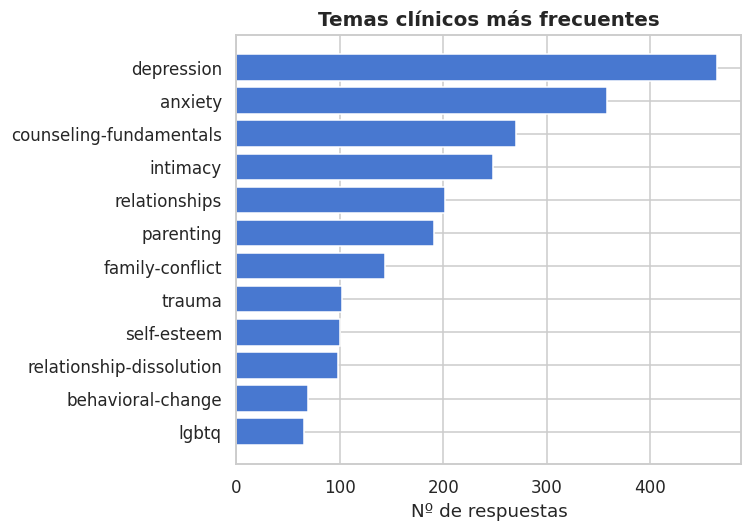

In [120]:
fig, ax = plt.subplots(figsize=(7, 5))

top_temas = temas.head(12)

ax.barh(
    top_temas.index[::-1],
    top_temas["n_respuestas"][::-1],
    edgecolor="white"
)

ax.set_title("Temas clínicos más frecuentes")
ax.set_xlabel("Nº de respuestas")

plt.tight_layout()
plt.savefig("figura_temas.png", dpi=200, bbox_inches="tight")
plt.show()

Figura síntesis (combina tres vistas del mismo fenómeno en una sola figura):

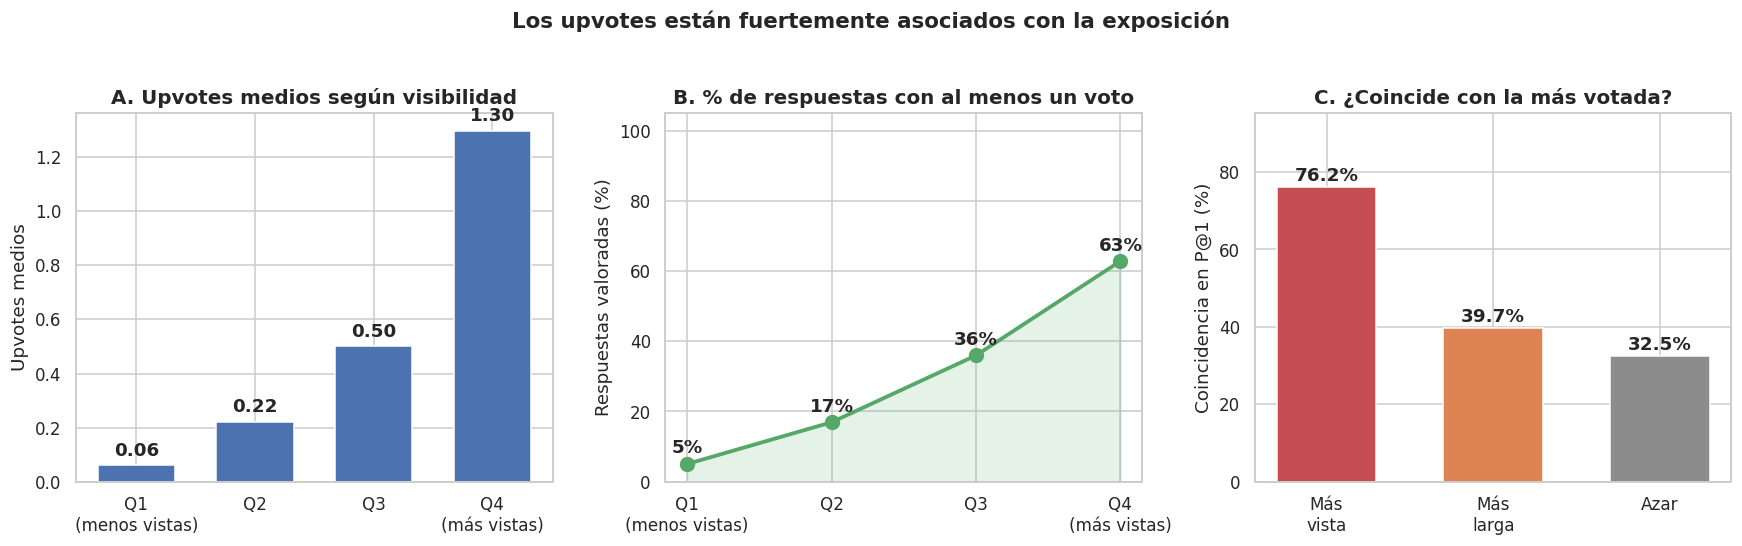

In [121]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: a más visualizaciones, más upvotes (relación creciente)
df_v = df.copy()
df_v["cuartil_views"] = pd.qcut(df_v["views"], 4,
                                labels=["Q1\n(menos vistas)", "Q2", "Q3", "Q4\n(más vistas)"])
resumen_v = df_v.groupby("cuartil_views", observed=True).agg(
    upvotes_medios=("upvotes", "mean"),
    pct_con_upvotes=("upvotes", lambda x: (x > 0).mean() * 100)
)

x = np.arange(4)
axes[0].bar(x, resumen_v["upvotes_medios"], color="#4C72B0", edgecolor="white", width=0.65)
axes[0].set_title("A. Upvotes medios según visibilidad")
axes[0].set_ylabel("Upvotes medios")
axes[0].set_xticks(x)
axes[0].set_xticklabels(resumen_v.index)
for i, v in enumerate(resumen_v["upvotes_medios"]):
    axes[0].text(i, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontweight="bold")

# Panel B: proporción de respuestas valoradas según visibilidad
axes[1].plot(x, resumen_v["pct_con_upvotes"], marker="o", markersize=9,
             linewidth=2.5, color="#55A868")
axes[1].fill_between(x, resumen_v["pct_con_upvotes"], alpha=0.15, color="#55A868")
axes[1].set_title("B. % de respuestas con al menos un voto")
axes[1].set_ylabel("Respuestas valoradas (%)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(resumen_v.index)
axes[1].set_ylim(0, 105)
for i, v in enumerate(resumen_v["pct_con_upvotes"]):
    axes[1].text(i, v + 3, f"{v:.0f}%", ha="center", fontweight="bold")

# Panel C: ¿qué criterio superficial "adivina" la más votada?
# Reutilizo los resultados ya calculados en los bloques anteriores
criterios = ["Más\nvista", "Más\nlarga", "Azar"]
valores_c = [
    round(n_coinc_v / len(coinc_views) * 100, 1),   # más vista
    round(n_coincide / n_total * 100, 1),           # más larga
    round(azar, 1)                                  # baseline aleatorio
]
colores_c = ["#C44E52", "#DD8452", "#8C8C8C"]
barras = axes[2].bar(criterios, valores_c, color=colores_c, edgecolor="white", width=0.6)
axes[2].set_title("C. ¿Coincide con la más votada?")
axes[2].set_ylabel("Coincidencia en P@1 (%)")
axes[2].set_ylim(0, max(valores_c) * 1.25)
for barra, v in zip(barras, valores_c):
    axes[2].text(barra.get_x() + barra.get_width() / 2, v + 1.5,
                 f"{v:.1f}%", ha="center", fontweight="bold")

fig.suptitle("Los upvotes están fuertemente asociados con la exposición",
             fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("figura_upvotes_exposicion.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretación: los *upvotes* reflejan principalmente exposición

Este análisis constituye el hallazgo más relevante del estudio exploratorio,
al cuestionar de forma directa la validez de la señal de referencia empleada.

**Los temas clínicos presentan una distribución desequilibrada.** Depresión
(465 respuestas) y ansiedad (358) concentran el mayor volumen, mientras que
temas como trastornos alimentarios (16) o estrés (13) están escasamente
representados. Se observa además que los temas minoritarios tienden a presentar
mayores tasas de valoración, *legal-regulatory* alcanza un 92,9 % de respuestas
con *upvotes* frente al 26,2 % de depresión, lo que sugiere que la propia
dinámica de la plataforma influye en la señal.

**Existe una asociación sustancial entre visualizaciones y *upvotes*.** Los
coeficientes de correlación (Pearson 0,434; Spearman 0,502) son
considerablemente superiores a los obtenidos para la longitud (0,128 y 0,151).
El análisis por cuartiles resulta especialmente ilustrativo: las respuestas
menos vistas (media de 47,6 visualizaciones) obtienen 0,06 *upvotes* de media y
solo un 5,0 % recibe alguna valoración, mientras que las más vistas (media de
981,3 visualizaciones) alcanzan 1,30 *upvotes* de media y un 62,8 % recibe al
menos una valoración.

**El contraste intra-pregunta confirma la magnitud del fenómeno.** En las 214
preguntas con señal inequívoca, la respuesta más votada coincide con la más
vista en el **76,2 %** de los casos, frente al 39,7 % que se obtiene aplicando
el criterio de mayor extensión y al 32,5 % esperado por selección aleatoria.

**Implicaciones.** Los resultados muestran que las respuestas más vistas
tienden a recibir más valoraciones, con una relación muy superior a la de
cualquier otra característica analizada. El análisis permite afirmar que ambas
variables están asociadas, pero no que una sea causa de la otra, ya que para
demostrar una causa haría falta un experimento controlado y no la simple
observación de los datos. Lo relevante para este trabajo es que la señal de
valoración está estrechamente ligada a la visibilidad de la respuesta, por lo
que no puede interpretarse como un reflejo directo de su calidad terapéutica:
una respuesta apropiada que haya sido poco vista difícilmente acumulará
valoraciones.

En consecuencia, el criterio de mayor número de visualizaciones constituye un
baseline exigente (76,2 % en Precision@1) que los sistemas propuestos deberán
superar para demostrar que capturan aspectos de calidad que van más allá de la
visibilidad. Esta limitación se retoma en el capítulo de discusión.

## BLOQUE 7: Síntesis del análisis exploratorio

Este apartado recopila las cifras clave obtenidas y las decisiones de diseño
que se derivan de ellas, y que se aplicarán en la fase de construcción del
conjunto de datos para la tarea de ranking.

In [122]:
sintesis = pd.DataFrame({
    "valor": [
        len(df),
        df["questionID"].nunique(),
        dos_o_mas,
        ganador_claro,
        round(ganador_claro / df["questionID"].nunique() * 100, 1),
        round(azar, 1),
        round(n_coincide / n_total * 100, 1),
        round(n_coinc_v / len(coinc_views) * 100, 1)
    ]
}, index=[
    "Respuestas totales",
    "Preguntas totales",
    "Preguntas rankeables (2+ respuestas)",
    "Preguntas con señal inequívoca (conjunto de evaluación)",
    "Porcentaje del total retenido para evaluación (%)",
    "Baseline aleatorio: Precision@1 esperada (%)",
    "Baseline de longitud: Precision@1 (%)",
    "Baseline de visualizaciones: Precision@1 (%)"
])
display(sintesis)

,valor
Respuestas totales,2775.0
Preguntas totales,940.0
Preguntas rankeables (2+ respuestas),460.0
Preguntas con señal inequívoca (conjunto de evaluación),214.0
Porcentaje del total retenido para evaluación (%),22.8
Baseline aleatorio: Precision@1 esperada (%),32.5
Baseline de longitud: Precision@1 (%),39.7
Baseline de visualizaciones: Precision@1 (%),76.2


### Conclusiones del análisis exploratorio

El estudio exploratorio de CounselChat permite extraer cuatro conclusiones
principales, que condicionan tanto la construcción del conjunto de evaluación
como la interpretación de los resultados posteriores.

**1. Solo una fracción del conjunto de datos es utilizable para la tarea de
ranking.** De las 940 preguntas disponibles, únicamente 460 (48,9 %) cuentan
con dos o más respuestas y son, por tanto, susceptibles de ordenación.

**2. La señal de calidad es inequívoca en menos de la mitad de esos casos.** De
las 460 preguntas rankeables, 184 (40,0 %) presentan todas sus respuestas sin
valoración alguna y 62 (13,5 %) muestran empate en el valor máximo. El conjunto
efectivo de evaluación queda constituido por 214 preguntas, un 22,8 % del total
inicial.

**3. Existe un sesgo de longitud de magnitud reducida.** Las respuestas más
extensas reciben más valoraciones de forma consistente, si bien la asociación
es débil (Spearman 0,151) y el criterio de mayor extensión solo alcanza un
39,7 % de acierto frente al 32,5 % esperado por azar.

**4. Los *upvotes* reflejan principalmente exposición.** La asociación entre
visualizaciones y valoraciones (Spearman 0,502) es sustancialmente superior a
la observada para cualquier otra característica analizada, y el criterio de
mayor número de visualizaciones alcanza un 76,2 % de acierto. Este resultado
constituye la principal limitación identificada en la señal de referencia.

**Decisiones derivadas para la fase experimental:**

- El conjunto de evaluación principal se restringirá a las 214 preguntas con una única respuesta de valoración máxima. Las 62 preguntas con empate se reservan para un análisis de robustez que las incorpora (276 preguntas), admitiendo como acierto cualquiera de las respuestas empatadas.

- Se eliminarán las 26 respuestas con texto vacío (answerText ausente), ya que
una respuesta sin contenido no puede ordenarse ni evaluarse.

- Para las 139 preguntas sin texto (questionText ausente) se recurrirá al campo
questionTitle como fuente alternativa de contenido, tras verificar en qué
medida resulta suficiente para representar la pregunta.

- Se incorporarán tres baselines derivados de este análisis: selección aleatoria (32,5 %), mayor extensión (39,7 %) y mayor número de visualizaciones (76,2 %), que los sistemas propuestos deberán superar.

- La señal débil de los upvotes, y en particular su asociación con la exposición, se considerará al interpretar los resultados y se abordará en la discusión.

Estas decisiones se revisaron en los notebooks posteriores. Finalmente se evaluaron las 276 preguntas (contando como acierto cualquier respuesta empatada), se mantuvieron las respuestas vacías y no se usaron las visualizaciones como baseline.